In [ ]:
# Purpose:
#   Integrate finalized level-3 immune cell annotations across all major lineages
#   into a unified Seurat object, and export harmonized RNA + ADT data for downstream
#   cross-platform and Python-based analyses.
#
# Summary:
#   - Load finalized, lineage-specific Seurat objects (B, T, DC, Mono, NK)
#   - Extract and merge standardized metadata fields across cell types
#   - Subset the integrated Seurat object to cells with curated level-3 annotations
#   - Propagate cell-cycle scores and level-3 cell-type labels into the full dataset
#   - Visualize global cell-type structure using UMAP
#   - Exclude outlier sample (29-I, aka, Pool137_32)
#   - Convert the final Seurat object to AnnData (h5ad) format
#   - Export imputed ADT expression matrix for downstream analysis
#   - Identify marker genes for major immune cell classes

# Header

In [2]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes_v1/functions.R')
library(Seurat)
library(SeuratData)
library(patchwork)
library(MuDataSeurat)
library(dplyr)

options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers


── Installed datasets ──────────────────────────────── SeuratData v0.2.2.9002 ──

✔ pbmcref 1.0.0                         


────────────────────────────────────── Key ─────────────────────────────────────

✔ Dataset loaded successfully
❯ Dataset built with a newer version of Seurat than installed
❓ Unknown version of Seurat installed




# Clean Data

In [3]:
celltypes = c('B','CD4 T','CD8 T','other T','DC','Mono','NK')


colnames_meta = c(
    'nFeaturess_RNA','nFeaturess_RNA_by_counts','total_counts','total_counts_mt','pct_counts_mt','doublets_pred','doublets_score','nCount_RNA','nFeature_RNA','percent.mt','predicted.celltype.l1.score','predicted.celltype.l1','predicted.celltype.l2.score','predicted.celltype.l2','predicted.celltype.l3.score','predicted.celltype.l3','mapping.score','seurat_clusters','dataset_name','S.Score','G2M.Score','Phase','old.ident','celltype_level3'
)

ct = 0
for (celltype in celltypes){

    ct = ct + 1
    
    fname = glue('data/03_cleandata/ft_{celltype}.qs')
    obj = qs::qread(fname)
    meta = obj@meta.data

    if (ct ==1){meta_master = meta[,colnames_meta]} else 
    {meta_master = rbind(meta_master, 
                         meta[,colnames_meta])}
}

In [4]:
dat = qs::qread("data/03_cleandata/itg_all.qs")
dat

An object of class Seurat 
28202 features across 444793 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [5]:
# Subset dat based on meta_master cell names
dat_fi = subset(dat, cells = intersect(Cells(dat), rownames(meta_master)))

# Identify columns in meta_master to add
cols_to_add = c("S.Score", "G2M.Score", "Phase", "celltype_level3")

# Add these columns to dat_fi metadata
for (col in cols_to_add) {
  if (col %in% colnames(meta_master)) {
    dat_fi@meta.data[[col]] = meta_master[Cells(dat_fi), col]
  } else {
    warning(glue("Column '{col}' not found in meta_master"))
  }
}

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



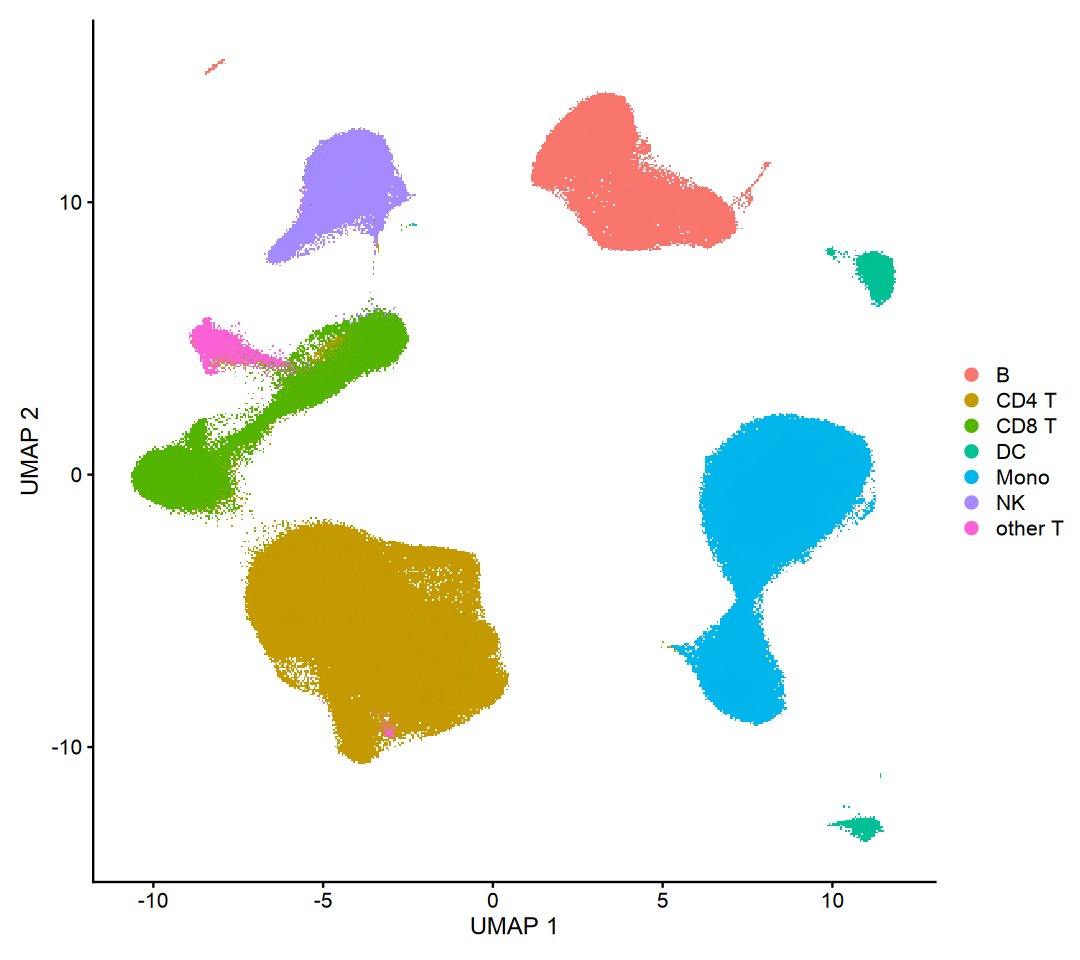

In [6]:
options(repr.plot.width=9, repr.plot.height=8)

fig <- DimPlot(dat_fi, 
               reduction = "umap", 
               group.by = "predicted.celltype.l1") +
  labs(
    title = NULL,            # Remove title
    x = "UMAP 1",            # Set x-axis label
    y = "UMAP 2"             # Set y-axis label
  )

fig

# Conversion to h5ad

First, restart kernel

In [1]:
library(reticulate)
use_python("/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/bin/python", required = TRUE)

# Verify we're using the right Python & that anndata is present
py_config()
py_module_available("anndata") 

Warning message in normalizePath(file.path(dirname(conda), "activate")):
“path[1]="/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/bin/activate": No such file or directory”
Warning message in normalizePath(file.path(dirname(conda), "activate")):
“path[1]="/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/bin/activate": No such file or directory”
Warning message in normalizePath(file.path(dirname(conda), "activate")):
“path[1]="/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/bin/activate": No such file or directory”


python:         /n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/bin/python
libpython:      /n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/libpython3.12.so
pythonhome:     /n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new:/n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new
version:        3.12.11 | packaged by conda-forge | (main, Jun  4 2025, 14:45:31) [GCC 13.3.0]
numpy:          /n/data1/dfci/surgonc/mittendorf/lab/chelsea/packages/miniconda3/envs/scrna_new/lib/python3.12/site-packages/numpy
numpy_version:  1.26.4

NOTE: Python version was forced by use_python() function

[1] TRUE

In [2]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
library(Seurat)
library(qs)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


qs 0.27.3. Announcement: https://github.com/qsbase/qs/issues/103



In [3]:
dat = qs::qread('data/03_cleandata/ft_all.qs')
dat

An object of class Seurat 
28202 features across 434565 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

## save RNA

In [4]:
# Convert RNA
dat[["RNA"]] <- as(dat[["RNA"]], "Assay")

Warning message:
“Assay RNA changing from Assay5 to Assay”


In [5]:
dat@assays <- dat@assays[c("RNA", "impADT")]
dat@active.assay <- "RNA" # drop all other assays

In [6]:
sceasy::convertFormat(dat, 
                      from="seurat", 
                      to="anndata",
                      outFile='data/03_cleandata/ft_all.h5ad')

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the sceasy package.
  Please report the issue to the authors.”
Warning message in .regularise_df(obj@meta.data, drop_single_values = drop_single_values):
“Dropping single category variables:doublets_pred”


AnnData object with n_obs × n_vars = 434565 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standardized', 'vf_vst_counts.Pool137_11_variable', 'vf_vst_counts.Pool137

## save impADT

In [13]:
impADT_mat <- GetAssayData(dat, assay = "impADT", slot = "data")  # or "counts" if you prefer raw counts
impADT_df <- as.data.frame(as.matrix(impADT_mat))

dim(impADT_df)
impADT_df[1:3,1:5]

[1]    228 441317

,Pool137_10_AAACCTGAGACTCGGA-1,Pool137_10_AAACCTGAGATCTGCT-1,Pool137_10_AAACCTGAGATTACCC-1,Pool137_10_AAACCTGAGCTGCGAA-1,Pool137_10_AAACCTGAGGACACCA-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CD39,0.5347714,1.4494152,0.4522654,0.4571837,1.3336056
Rat-IgG1-1,0.7856641,0.6671984,0.7443625,0.7436867,0.5148646
CD107a,1.0658876,1.4096133,0.9509500,1.0070761,1.6416948


In [15]:
write.csv(t(impADT_df), file = "data/03_cleandata/ft_all_impADT.csv")

# DEGs (major cell types)

In [16]:
Idents(dat) <- "predicted.celltype.l1"

markers = FindAllMarkers(dat, verbose = T)

head(markers)

Calculating cluster CD4 T

Calculating cluster Mono

Calculating cluster CD8 T

Calculating cluster NK

Calculating cluster B

Calculating cluster DC

Calculating cluster other T



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
IL7R,0,2.660791,0.896,0.178,0,CD4 T,IL7R
CD3E,0,1.682244,0.920,0.269,0,CD4 T,CD3E
TCF7,0,2.562703,0.811,0.176,0,CD4 T,TCF7
ZEB2,0,-6.811995,0.018,0.648,0,CD4 T,ZEB2
LYN,0,-7.852420,0.008,0.615,0,CD4 T,LYN
HLA-DRA,0,-7.301499,0.026,0.616,0,CD4 T,HLA-DRA


In [17]:
markers

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
IL7R,0,2.660791,0.896,0.178,0,CD4 T,IL7R
CD3E,0,1.682244,0.920,0.269,0,CD4 T,CD3E
TCF7,0,2.562703,0.811,0.176,0,CD4 T,TCF7
ZEB2,0,-6.811995,0.018,0.648,0,CD4 T,ZEB2
LYN,0,-7.852420,0.008,0.615,0,CD4 T,LYN
HLA-DRA,0,-7.301499,0.026,0.616,0,CD4 T,HLA-DRA
HLA-DRB1,0,-5.331291,0.062,0.650,0,CD4 T,HLA-DRB1
IL32,0,1.199534,0.894,0.308,0,CD4 T,IL32
INPP4B,0,3.776031,0.655,0.079,0,CD4 T,INPP4B


In [18]:
write.csv(markers, 
          'data/04_markergenes/all_majorCellTypes.csv')

# Export to RDS (GEO)

https://www.ncbi.nlm.nih.gov/geo/info/seq.html

In [4]:
dat = qs::qread("data/03_cleandata/ft_all.qs")
dat 

An object of class Seurat 
28202 features across 434565 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
length(unique(dat@meta.data$dataset_name))

[1] 55